In [1]:
# Cell 1: Environment Setup, High-Performance Parquet Ingestion & Plot Configuration
import sys
from pathlib import Path

# Ensure project root is available in sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import PROCESSED_DATA_DIR, DUCKDB_PATH

# Visual aesthetics configuration for publication-ready figures
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

# Read the sanitized analytical dataset from Apache Parquet
parquet_path = PROCESSED_DATA_DIR / "housing_clean.parquet"
df = pd.read_parquet(parquet_path)

print(f"Loaded clean dataset from: {parquet_path.name}")
print(f"Dimensions: {df.shape[0]:,} rows | {df.shape[1]} columns")

# Inspect core initial identifiers
df[["order_id", "neighborhood", "gr_liv_area", "overall_qual", "sale_price"]].head(3)

Loaded clean dataset from: housing_clean.parquet
Dimensions: 2,412 rows | 82 columns


,order_id,neighborhood,gr_liv_area,overall_qual,sale_price
0,1,NAmes,1656,6,215000
1,2,NAmes,896,5,105000
2,3,NAmes,1329,6,172000


--- Raw Sale Price ---
Skewness : 1.594 (Values > 0.5 indicate significant right skew)
Kurtosis : 4.390 (High values indicate heavy, fat tails)

--- Log-Transformed Sale Price ln(SalePrice) ---
Skewness : 0.133 (Close to 0 indicates symmetrical distribution)
Kurtosis : 0.602 (Close to 0 indicates normal mesokurtic tails)


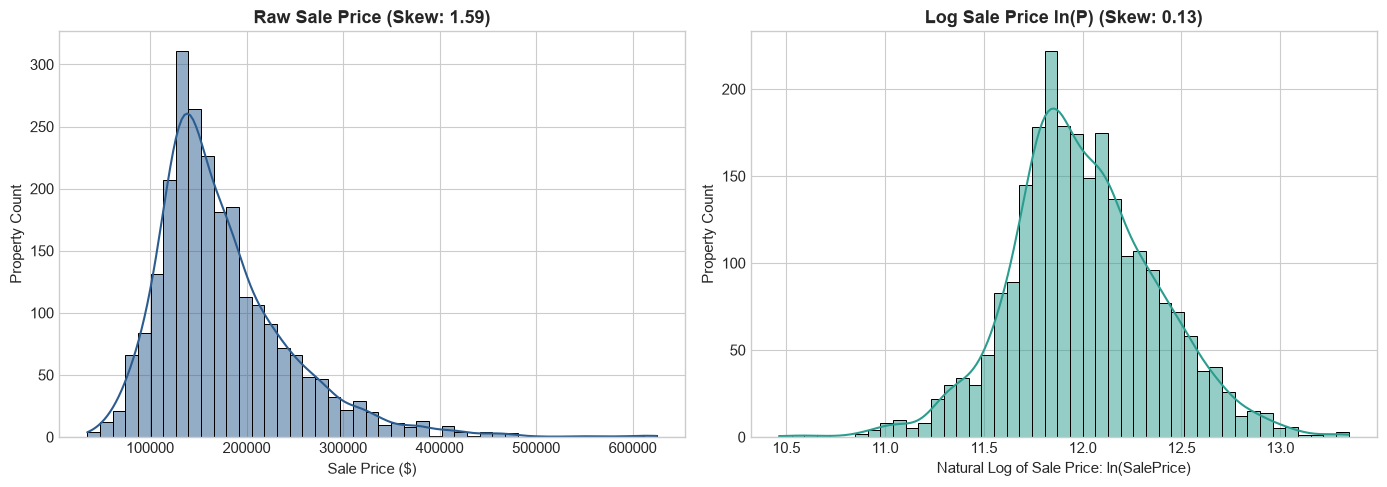

In [2]:
# Cell 2: Target Variable Distribution & Log Transformation Diagnostics
price = df["sale_price"]
log_price = np.log(price)

# Compute statistical moments
raw_skew = stats.skew(price)
raw_kurt = stats.kurtosis(price)

log_skew = stats.skew(log_price)
log_kurt = stats.kurtosis(log_price)

print(f"--- Raw Sale Price ---")
print(f"Skewness : {raw_skew:.3f} (Values > 0.5 indicate significant right skew)")
print(f"Kurtosis : {raw_kurt:.3f} (High values indicate heavy, fat tails)")

print(f"\n--- Log-Transformed Sale Price ln(SalePrice) ---")
print(f"Skewness : {log_skew:.3f} (Close to 0 indicates symmetrical distribution)")
print(f"Kurtosis : {log_kurt:.3f} (Close to 0 indicates normal mesokurtic tails)")

# Plotting Side-by-Side Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Raw Price (Right-skewed long tail)
sns.histplot(price, kde=True, ax=axes[0], color="#2b5c8f", bins=45)
axes[0].set_title(f"Raw Sale Price (Skew: {raw_skew:.2f})", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Sale Price ($)")
axes[0].set_ylabel("Property Count")

# Subplot 2: Log-Transformed Price (Symmetrical Bell Curve)
sns.histplot(log_price, kde=True, ax=axes[1], color="#2a9d8f", bins=45)
axes[1].set_title(f"Log Sale Price ln(P) (Skew: {log_skew:.2f})", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Natural Log of Sale Price: ln(SalePrice)")
axes[1].set_ylabel("Property Count")

plt.tight_layout()
plt.show()

# Persist log_sale_price into the active dataframe
df["log_sale_price"] = log_price

In [5]:
# Cell 3: Feature Engineering - Composite Econometric Metrics

# 1. Total Living Area (Above Ground + Total Basement)
df["total_living_sf"] = df["gr_liv_area"] + df["total_bsmt_sf"]

# 2. Total Bathrooms (combining full and half baths, above and below grade)
df["total_bathrooms"] = (
    df["full_bath"] 
    + (0.5 * df["half_bath"]) 
    + df["bsmt_full_bath"] 
    + (0.5 * df["bsmt_half_bath"])
)

# 3. Property Age at Sale & Years Since Remodel
df["property_age"] = df["yr_sold"] - df["year_built"]
df["years_since_remodel"] = df["yr_sold"] - df["year_remod_add"]

# Sanity check: Ensure negative ages do not exist (e.g. built in year after sale)
df["property_age"] = df["property_age"].clip(lower=0)
df["years_since_remodel"] = df["years_since_remodel"].clip(lower=0)

# Display sample of newly engineered features alongside target
engineered_cols = ["order_id", "total_living_sf", "total_bathrooms", "property_age", "years_since_remodel", "sale_price"]
df[engineered_cols].head()

,order_id,total_living_sf,total_bathrooms,property_age,years_since_remodel,sale_price
0,1,2736.0,2.0,50,50,215000
1,2,1778.0,1.0,49,49,105000
2,3,2658.0,1.5,52,52,172000
3,4,4220.0,3.5,42,42,244000
4,5,2557.0,2.5,13,12,189900


C:\Users\abine\AppData\Local\Temp\ipykernel_24096\193297949.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


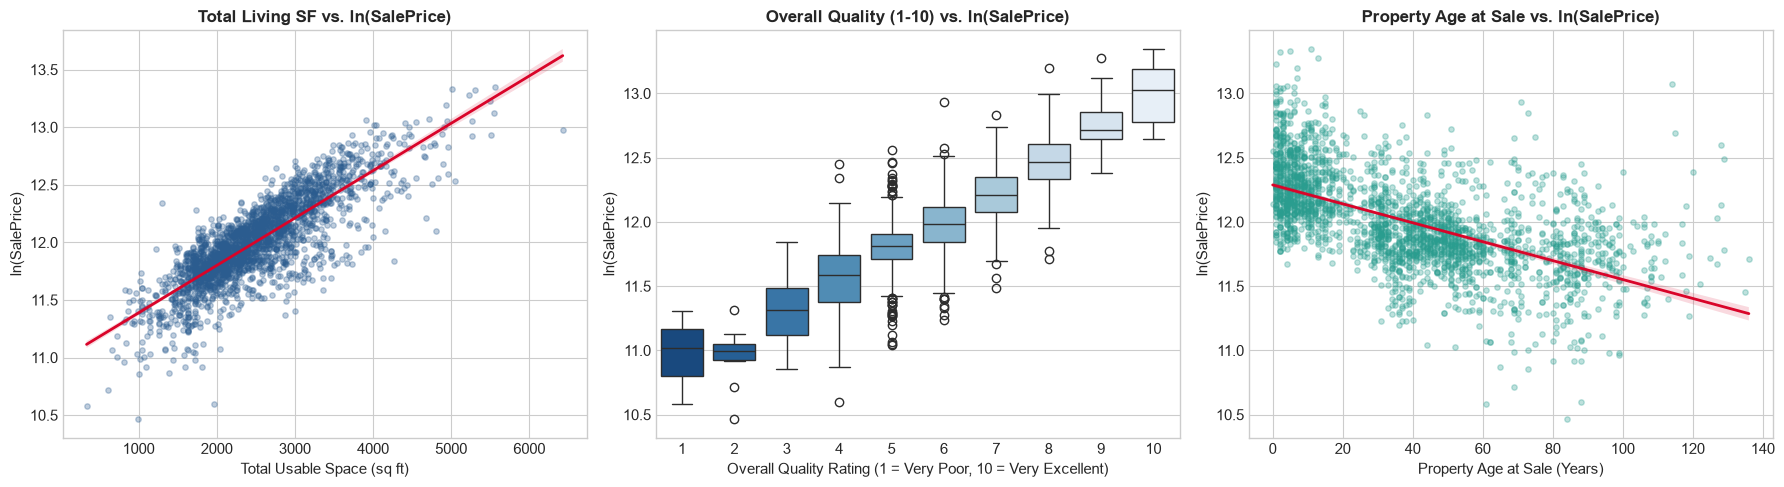

In [7]:
# Cell 4: Visualizing Primary Economic Value Drivers
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Living Space vs. Log Sale Price
sns.regplot(
    data=df, 
    x="total_living_sf", 
    y="log_sale_price", 
    ax=axes[0],
    scatter_kws={"alpha": 0.3, "color": "#2b5c8f", "s": 15},
    line_kws={"color": "#d90429", "linewidth": 2}
)
axes[0].set_title("Total Living SF vs. ln(SalePrice)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Total Usable Space (sq ft)")
axes[0].set_ylabel("ln(SalePrice)")

# 2. Overall Quality vs. Log Sale Price (Boxplot + Strip)
sns.boxplot(
    data=df, 
    x="overall_qual", 
    y="log_sale_price", 
    ax=axes[1],
    palette="Blues_r"
)
axes[1].set_title("Overall Quality (1-10) vs. ln(SalePrice)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Overall Quality Rating (1 = Very Poor, 10 = Very Excellent)")
axes[1].set_ylabel("ln(SalePrice)")

# 3. Property Age vs. Log Sale Price
sns.regplot(
    data=df, 
    x="property_age", 
    y="log_sale_price", 
    ax=axes[2],
    scatter_kws={"alpha": 0.3, "color": "#2a9d8f", "s": 15},
    line_kws={"color": "#d90429", "linewidth": 2}
)
axes[2].set_title("Property Age at Sale vs. ln(SalePrice)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Property Age at Sale (Years)")
axes[2].set_ylabel("ln(SalePrice)")

plt.tight_layout()
plt.show()

In [9]:
# Cell 5: Neighborhood Valuation Benchmarks via DuckDB SQL Window Functions
con = duckdb.connect(str(DUCKDB_PATH))

# First, attach our engineered columns into a temporary in-memory table
con.register("df_engineered", df)

neighborhood_benchmarks_sql = """
WITH neighborhood_summary AS (
    SELECT 
        neighborhood,
        COUNT(*) AS total_sales,
        ROUND(AVG(sale_price), 0)::INT AS mean_price,
        ROUND(MEDIAN(sale_price), 0)::INT AS median_price,
        ROUND(AVG(sale_price / total_living_sf), 2) AS avg_price_per_sqft,
        ROUND(STDDEV(sale_price), 0)::INT AS price_volatility
    FROM df_engineered
    GROUP BY neighborhood
),
citywide_metrics AS (
    SELECT 
        MEDIAN(sale_price) AS city_median_price,
        AVG(sale_price / total_living_sf) AS city_avg_ppsf
    FROM df_engineered
)
SELECT 
    ns.neighborhood,
    ns.total_sales,
    ns.median_price,
    ns.avg_price_per_sqft,
    ns.price_volatility,
    -- Calculate percentage premium over citywide median using scalar subquery
    ROUND(((ns.median_price - cm.city_median_price) / cm.city_median_price) * 100, 1) AS pct_premium_vs_city
FROM neighborhood_summary ns
CROSS JOIN citywide_metrics cm
WHERE ns.total_sales >= 20  -- Filter out fringe pockets with under 20 sales for statistical stability
ORDER BY ns.median_price DESC;
"""

df_neighborhoods = con.execute(neighborhood_benchmarks_sql).df()
con.close()

print(f"Top 5 Most Expensive vs. Bottom 5 Most Affordable Neighborhoods (min 20 sales):")
display(df_neighborhoods.head(5))
display(df_neighborhoods.tail(5))

Top 5 Most Expensive vs. Bottom 5 Most Affordable Neighborhoods (min 20 sales):


,neighborhood,total_sales,median_price,avg_price_per_sqft,price_volatility,pct_premium_vs_city
0,NoRidge,66,301750,83.09,73718,90.1
1,NridgHt,100,284000,85.77,95254,78.9
2,Veenker,22,257500,79.57,62899,62.2
3,StoneBr,35,251000,83.14,92931,58.1
4,Somerst,114,222250,82.25,53581,40.0


,neighborhood,total_sales,median_price,avg_price_per_sqft,price_volatility,pct_premium_vs_city
18,Edwards,155,125000,63.30,47453,-21.3
19,OldTown,204,122125,58.66,45066,-23.1
20,IDOTRR,68,116250,57.90,33553,-26.8
21,BrDale,26,107000,64.82,11383,-32.6
22,MeadowV,34,89375,57.93,20490,-43.7


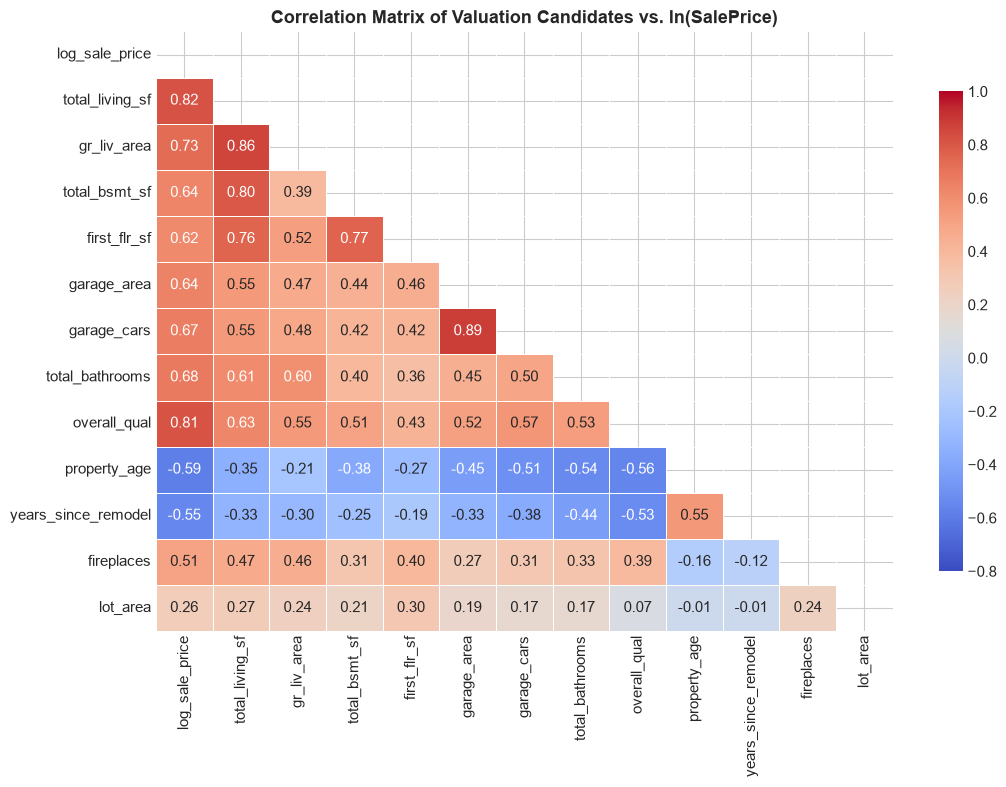

Correlation with ln(SalePrice) (Ranked):


log_sale_price         1.000000
total_living_sf        0.823513
overall_qual           0.811839
gr_liv_area            0.728378
total_bathrooms        0.680264
garage_cars            0.665863
garage_area            0.644445
total_bsmt_sf          0.637182
first_flr_sf           0.618078
fireplaces             0.507324
lot_area               0.263732
years_since_remodel   -0.551149
property_age          -0.587095
Name: log_sale_price, dtype: float64

In [11]:
# Cell 6: Correlation Analysis & Multicollinearity Screening

# Select continuous & discrete numeric candidates for valuation modeling
candidate_numeric = [
    "log_sale_price",
    "total_living_sf",
    "gr_liv_area",
    "total_bsmt_sf",
    "first_flr_sf",
    "garage_area",
    "garage_cars",
    "total_bathrooms",
    "overall_qual",
    "property_age",
    "years_since_remodel",
    "fireplaces",
    "lot_area"
]

# Compute Pearson Correlation Matrix
corr_matrix = df[candidate_numeric].corr()

# Plot publication-grade correlation heatmap
plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Mask the upper triangle to avoid redundant mirrored data

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-0.8, 
    vmax=1.0, 
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Matrix of Valuation Candidates vs. ln(SalePrice)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Print highest correlated features with the target variable
print("Correlation with ln(SalePrice) (Ranked):")
display(corr_matrix["log_sale_price"].sort_values(ascending=False))

In [13]:
# Cell 7: Variance Inflation Factor (VIF) Diagnostic Audit
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Define a baseline regression candidate list
vif_candidates = [
    "total_living_sf",
    "overall_qual",
    "total_bathrooms",
    "garage_cars",
    "garage_area",        # Expected to conflict with garage_cars
    "property_age",
    "years_since_remodel",
    "fireplaces",
    "lot_area"
]

# Extract feature matrix and add an intercept column (required for proper VIF calculation)
X_vif = df[vif_candidates].copy()
X_vif["Intercept"] = 1.0

# Calculate VIF for each feature
vif_records = []
for i, col in enumerate(X_vif.columns):
    if col != "Intercept":
        val = variance_inflation_factor(X_vif.values, i)
        vif_records.append({"feature": col, "VIF": round(val, 2)})

df_vif = pd.DataFrame(vif_records).sort_values(by="VIF", ascending=False)

print("Variance Inflation Factor (VIF) Diagnostic Report:")
print("Rule of thumb: VIF > 5 indicates multicollinearity; VIF > 10 requires pruning.")
display(df_vif)

Variance Inflation Factor (VIF) Diagnostic Report:
Rule of thumb: VIF > 5 indicates multicollinearity; VIF > 10 requires pruning.


,feature,VIF
3,garage_cars,5.30
4,garage_area,4.87
0,total_living_sf,2.50
1,overall_qual,2.49
2,total_bathrooms,2.03
5,property_age,1.98
6,years_since_remodel,1.65
7,fireplaces,1.37
8,lot_area,1.14


In [14]:
# Cell 8: Materialize Engineered Dataset for Econometric Modeling
from src.config import PROCESSED_DATA_DIR, DUCKDB_PATH

ENGINEERED_PARQUET_PATH = PROCESSED_DATA_DIR / "housing_engineered.parquet"

# 1. Export dataframe directly to Apache Parquet
df.to_parquet(ENGINEERED_PARQUET_PATH, index=False)
print(f"Exported engineered dataset to: {ENGINEERED_PARQUET_PATH.name}")

# 2. Materialize inside persistent DuckDB
con = duckdb.connect(str(DUCKDB_PATH))
con.register("df_final", df)
con.execute("CREATE OR REPLACE TABLE housing_engineered AS SELECT * FROM df_final")
con.close()

print(f"Persisted 'housing_engineered' into {DUCKDB_PATH.name}")
print(f"Final Phase 2 Shape: {df.shape[0]:,} rows | {df.shape[1]} columns")

Exported engineered dataset to: housing_engineered.parquet
Persisted 'housing_engineered' into housing.duckdb
Final Phase 2 Shape: 2,412 rows | 87 columns
